# 14주차 · 멀티모달 AI 웹앱 — 사진 · 음성 · 문서를 이해하는 AI

| 항목 | 내용 |
|---|---|
| 목표 | 글뿐 아니라 **사진 · 음성 · PDF** 를 Gemini 에 함께 보내고, 결과를 JSON 으로 정리해 **Streamlit 웹앱**으로 만듭니다 |
| 실행 방법 | 위에서부터 차례로 실행합니다. 예시 사진 · 음성 · PDF 는 실습 0-3 에서 코드로 직접 만듭니다 (남의 사진 · 목소리를 쓰지 않음) |
| 필요 계정 · 키 | 구글 계정 · Gemini API 키(Colab 보안 비밀 `GEMINI_API_KEY`) · GitHub · Streamlit Community Cloud(12주차 `streamlit-lab`) · Vercel(13주차 `my-ai-api`) |
| 요청 수 | 노트북 전체 1회 실행 = Gemini 요청 **18번**. 무료 한도가 **분당 15회**이므로 셀을 한꺼번에 실행하지 말고 차례로 실행하세요 (429 가 나오면 1분 기다림) |

### 멀티모달이란
**멀티모달(multimodal)** 은 글 · 사진 · 소리 · 문서처럼 **종류가 다른 입력을 함께 이해하는 것**입니다.
9~13주차에는 글만 보냈습니다. 오늘은 요청 하나에 **글 부분 + 사진(또는 음성 · PDF) 부분**을 함께 담아 보냅니다.

```python
input=[{"type": "text", "text": "이 영수증의 합계는?"},
       {"type": "image", "data": "...base64 글자...", "mime_type": "image/png"}]
```

### 오늘의 흐름
| 실습 | 하는 일 |
|---|---|
| A (STEP 0) | 설치 · 점검 · 앱 셀 도우미 · 예시 자료 만들기 |
| B (STEP 1) | 사진 한 장 보내기 — 영수증 읽기 · 그래프 읽기 |
| C (STEP 2) | 사진 → JSON — 영수증을 표로 정리하고 **코드로 검산** |
| D (STEP 3) | 음성 — 받아쓰기 · 말한 일정을 JSON 으로 |
| E (STEP 4) | 문서(PDF) — 안내문에서 필요한 것만 묻기 |
| F (STEP 5) | 크기와 토큰 — 사진을 줄여 보내기 |
| G (STEP 6~7) | 사진 · 음성 도우미 — 백엔드(FastAPI · Vercel) + 화면(Streamlit) 나눠 만들고 배포 |
| H (STEP 8) | 심화 ① 물체 위치 찾기 (상자 그리기) |
| I (STEP 9) | 심화 ② 사진 여러 장 비교 · 이어 묻기 |
| 과제 | 나만의 멀티모달 서비스 — 백엔드 + 화면 (사진 → 정해 둔 칸으로 정리) |

> ⚠ **개인정보** — 얼굴 · 신분증 · 카드 번호 · 남의 목소리가 담긴 사진 · 음성은 보내지 마세요. 무료 등급에 보낸 내용은 구글이 제품 개선에 쓸 수 있습니다.

---
# STEP 0. 준비 (실습 A)

In [2]:
# ============================================================
# [실습 0-1] [점검] 설치 · 버전 · 키 확인 (요청 1번)
# ------------------------------------------------------------
# espeak-ng : 예시 음성을 만드는 한국어 기계 목소리 · fonts-nanum : 예시 사진의 한글 글꼴 (약 20초)
# ============================================================
!apt-get -qq install -y espeak-ng fonts-nanum > /dev/null
!pip install -q streamlit==1.66.1 google-genai==2.12.1

import base64
import json

import google.genai
import PIL
import streamlit
from google import genai
from google.genai import types
from google.colab import userdata

print("streamlit   :", streamlit.__version__, "(1.66.1 이면 OK)")
print("google-genai:", google.genai.__version__, "(2.12.1 이면 OK)")
print("Pillow      :", PIL.__version__, "(사진 줄이기 · 그리기에 씀 — Colab 기본)")
import fastapi, uvicorn
print("fastapi     :", fastapi.__version__, "· uvicorn :", uvicorn.__version__, "(백엔드 실습 — Colab 기본)")

MODEL_NAME = "gemini-3.5-flash-lite"      # 글 · 사진 · 영상 · 음성 · PDF 입력을 모두 받는 모델
client = genai.Client(
    api_key=userdata.get("GEMINI_API_KEY"),
    http_options=types.HttpOptions(timeout=120_000, retry_options=types.HttpRetryOptions(http_status_codes=[500, 503])),
)
try:
    reply = client.interactions.create(model=MODEL_NAME, store=False, input="'키 점검 성공' 이라고만 답해 줘.")
    print("✅ 키가 동작합니다 — Gemini 의 답 :", reply.output_text)
except Exception as error:
    print("❌ 키 점검 실패 —", type(error).__name__, getattr(error, "status_code", None), "→ 9주차 키 발급 · Colab 보안 비밀을 확인하세요")

streamlit   : 1.66.1 (1.66.1 이면 OK)
google-genai: 2.12.1 (2.12.1 이면 OK)
Pillow      : 11.3.0 (사진 줄이기 · 그리기에 씀 — Colab 기본)
fastapi     : 0.141.1 · uvicorn : 0.54.0 (백엔드 실습 — Colab 기본)
✅ 키가 동작합니다 — Gemini 의 답 : 키 점검 성공


In [3]:
# ============================================================
# [실습 0-2] 서버 · 앱 셀 도우미 켜기 (요청 없음 · 런타임마다 한 번)
# ------------------------------------------------------------
# 이 셀을 실행한 뒤에는
#   · 첫 줄이 "# 📋 main.py" 인 셀을 실행하면 → main.py 로 저장 + API 서버를 (다시) 켜고 주소 목록을 보여 줌
#   · 첫 줄이 "# 📋 app.py"  인 셀을 실행하면 → app.py 로 저장 + 웹 화면 없이 점검 (12주차와 같음)
#   · call("GET", "/") 처럼 부르면 → API 에 요청을 보내고 상태 번호와 JSON 답을 보여 줌
# 오류가 없으면 그 셀 전체를 복사해 GitHub 의 main.py (또는 app.py) 에 붙여 넣을 수 있습니다.
# ============================================================
import json
import logging
import os
import subprocess
import time

import requests
from google.colab import userdata
from streamlit.testing.v1 import AppTest

logging.getLogger("streamlit.runtime.scriptrunner_utils.script_run_context").disabled = True

server_process = None      # 뒤에서 돌고 있는 API 서버 (uvicorn)
ACCESS_CODE = None         # 실습 6 에서 접근 코드를 정하면 서버 환경 변수 APP_ACCESS_CODE 로 넘겨줌


def start_server():
    """main.py 를 uvicorn 으로 (다시) 켠다 — 셀이 끝나도 뒤에서 계속 돎"""
    global server_process
    if server_process is not None and server_process.poll() is None:
        server_process.terminate()                       # 전에 켜 둔 서버는 끄고
        server_process.wait()
    env = dict(os.environ, GEMINI_API_KEY=userdata.get("GEMINI_API_KEY"))   # 키는 환경 변수로만 전달
    if ACCESS_CODE:
        env["APP_ACCESS_CODE"] = ACCESS_CODE
    server_process = subprocess.Popen(["uvicorn", "main:app", "--port", "8000"], env=env,
                                      stdout=open("server.log", "w"), stderr=subprocess.STDOUT)
    for _ in range(60):                                  # 최대 15초 기다림
        time.sleep(0.25)
        if server_process.poll() is not None:            # 켜지다가 멈췄으면 (main.py 오류)
            break
        try:
            return requests.get("http://localhost:8000/openapi.json", timeout=2).json()
        except requests.RequestException:
            pass
    print("❌ 서버가 켜지지 않음 — 서버 기록(server.log) 마지막 부분 :")
    print(open("server.log", encoding="utf-8").read()[-1500:])
    return None


def save_and_serve(source):
    """셀 내용을 main.py 로 저장하고 서버를 다시 켠 뒤, 만든 주소(엔드포인트) 목록을 보여 준다"""
    with open("main.py", "w", encoding="utf-8") as main_file:
        main_file.write(source)
    try:
        compile(source, "main.py", "exec")               # 먼저 문법(괄호 · 따옴표 · 들여쓰기)만 검사
    except SyntaxError as error:
        print(f"❌ 문법 오류 — {error.lineno}번째 줄 : {error.msg} → 고친 뒤 다시 실행하세요 (GitHub 에 올리지 않음)")
        return
    spec = start_server()
    if spec is None:
        return
    print("✅ main.py 저장 · API 서버 켜짐 — 만든 주소 :")
    for path, methods in spec["paths"].items():
        for method in methods:
            print(f"   · {method.upper():5} {path}")
    print("ℹ️ 서버는 Colab 컴퓨터 안(localhost:8000)에 있음 — 내 PC 브라우저 주소창으로는 열리지 않음 → 아래 🧪 셀의 call() 로 부르기")
    print("👉 배포할 때는 이 셀 전체를 복사(Ctrl+A → Ctrl+C) → GitHub 의 main.py 에 붙여 넣기 → Commit")


def call(method, path, body=None, headers=None, base="http://localhost:8000"):
    """API 를 부르고 상태 번호와 JSON 답을 보기 좋게 보여 준다 — 응답 객체를 돌려줌"""
    try:
        response = requests.request(method, base + path, json=body, headers=headers, timeout=90)
    except requests.RequestException as error:
        print(f"❌ {base} 에 닿지 못함 —", type(error).__name__)
        return None
    print(f"{method} {path} → 상태 번호 {response.status_code}")
    try:
        print(json.dumps(response.json(), ensure_ascii=False, indent=2)[:1500])
    except ValueError:
        print(response.text[:500])
    return response


def open_app():
    """app.py 를 웹 화면 없이 처음 화면까지 실행해 돌려준다 (12주차 도우미와 같음)"""
    app_test = AppTest.from_file(os.path.abspath("app.py"), default_timeout=120)
    return app_test.run()


def save_and_check_app(source):
    """셀 내용을 app.py 로 저장하고 웹 화면 없이 한 번 실행해 본다"""
    with open("app.py", "w", encoding="utf-8") as app_file:
        app_file.write(source)
    try:
        compile(source, "app.py", "exec")
    except SyntaxError as error:
        print(f"❌ 문법 오류 — {error.lineno}번째 줄 : {error.msg}")
        return
    app_test = open_app()
    if app_test.exception:
        print("❌ 앱 실행 중 오류 —", app_test.exception[0].value)
        return
    print("✅ 오류 없음 — app.py 로 저장했습니다. 처음 화면 :", [t.value for t in app_test.title],
          "/ 입력칸 :", [w.label for w in app_test.text_input], "/ 버튼 :", [b.label for b in app_test.button])


def code_cell(lines):
    """첫 줄이 '# 📋 main.py' · '# 📋 app.py' 인 셀은 실행하는 대신 저장 + 점검으로 바꾼다"""
    if lines and lines[0].startswith("# 📋 main.py"):
        return [f"save_and_serve({''.join(lines)!r})\n"]
    if lines and lines[0].startswith("# 📋 app.py"):
        return [f"save_and_check_app({''.join(lines)!r})\n"]
    return lines


transformers = get_ipython().input_transformers_cleanup
transformers[:] = [t for t in transformers if getattr(t, "__name__", "") != "code_cell"]   # 두 번 실행해도 하나만
transformers.append(code_cell)
print("✅ 도우미 준비 완료 — '# 📋 main.py' 셀 = 저장 + 서버 켜기 · call() = API 부르기")

✅ 도우미 준비 완료 — '# 📋 main.py' 셀 = 저장 + 서버 켜기 · call() = API 부르기


> ⚠️ **런타임이 다시 시작되면** 도우미와 뒤에서 돌던 API 서버가 사라집니다. 📋 셀을 실행했는데 아무것도 출력되지 않거나 `call` 이 NameError 면 → 0-1 · 0-2 를 다시 실행하세요.
> 0-2 는 13주차 도우미와 같습니다 — `# 📋 main.py` 셀 = 저장 + 서버 켜기 · `call()` = API 부르기 · `# 📋 app.py` 셀 = 저장 + 웹 화면 없이 점검.

In [4]:
# ============================================================
# [실습 0-3] 실습용 예시 자료 만들기 — 사진 2장 · 음성 2개 · PDF 1개 (요청 없음)
# ------------------------------------------------------------
# 인터넷에서 남의 사진 · 목소리를 가져오지 않고, 코드로 직접 만듭니다 (저작권 · 개인정보 걱정 없음)
# 정답을 우리가 알고 있으므로, AI 가 맞게 읽었는지 확인할 수 있습니다
# ============================================================
import os
import subprocess
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image, ImageDraw, ImageFont

FONT = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"           # 0-1 에서 설치한 한글 글꼴
font_manager.fontManager.addfont(FONT)
matplotlib.rcParams["font.family"] = font_manager.FontProperties(fname=FONT).get_name()

# ① 영수증 사진 (receipt.png) — 정답 : 합계 15,300원
RECEIPT_ITEMS = [("아메리카노", 2, 4500), ("크루아상", 1, 3800), ("치즈케이크", 1, 2500)]
image = Image.new("RGB", (480, 560), "white")
draw = ImageDraw.Draw(image)
big, small = ImageFont.truetype(FONT, 30), ImageFont.truetype(FONT, 22)
draw.text((140, 30), "폴리 카페", font=big, fill="black")
draw.text((40, 85), "2026-11-18  12:31   (테이블 3)", font=small, fill="gray")
draw.line((40, 125, 440, 125), fill="black", width=2)
y = 145
for name, count, price in RECEIPT_ITEMS:
    draw.text((40, y), name, font=small, fill="black")
    draw.text((250, y), f"x{count}", font=small, fill="black")
    draw.text((330, y), f"{count * price:,}원", font=small, fill="black")
    y += 45
draw.line((40, y + 10, 440, y + 10), fill="black", width=2)
total = sum(count * price for _, count, price in RECEIPT_ITEMS)
draw.text((40, y + 30), "합계", font=big, fill="black")
draw.text((300, y + 30), f"{total:,}원", font=big, fill="black")
draw.text((40, y + 100), "카드 결제 · 감사합니다", font=small, fill="gray")
image.save("receipt.png")

# ② 그래프 사진 (chart.png) — 정답 : 9월 42 · 10월 57 · 11월 35 (단위 : 명)
plt.figure(figsize=(5, 3.2))
plt.bar(["9월", "10월", "11월"], [42, 57, 35], color=["#4472C4", "#ED7D31", "#A5A5A5"])
plt.title("학과 도서관 하루 평균 방문자 (명)")
plt.tight_layout()
plt.savefig("chart.png", dpi=120)
plt.close()

# ③ 음성 2개 (voice.wav · command.wav) — espeak-ng 의 한국어 목소리 (기계 음성)
VOICE_TEXT = "오늘 점심은 학생 식당에서 김치찌개를 먹었습니다. 가격은 오천 원이고, 맛은 조금 짰습니다."
COMMAND_TEXT = "내일 오후 세 시에 도서관 세미나실에서 팀 회의 일정을 잡아 줘."
subprocess.run(["espeak-ng", "-v", "ko", "-s", "150", "-w", "voice.wav", VOICE_TEXT], check=True)
subprocess.run(["espeak-ng", "-v", "ko", "-s", "150", "-w", "command.wav", COMMAND_TEXT], check=True)

# ④ 안내문 PDF (notice.pdf) — 정답 : 신청 마감 11월 28일 · 장소 공학관 302호 · 준비물 노트북
plt.figure(figsize=(8.27, 11.69))                                 # A4 크기
plt.axis("off")
NOTICE = ["[학과 공지] 2026 겨울방학 AI 특강 안내", "",
          "· 일시 : 12월 15일(화) ~ 12월 17일(목), 오후 1시 ~ 4시",
          "· 장소 : 공학관 302호",
          "· 대상 : 인공지능소프트웨어과 1학년 (선착순 20명)",
          "· 내용 : 멀티모달 AI 로 사진 · 음성 앱 만들기",
          "· 준비물 : 개인 노트북 (충전기 포함)",
          "· 신청 : 11월 28일(토)까지 학과 사무실 방문 신청", "",
          "※ 3일 모두 참석한 학생에게 수료증을 드립니다."]
for line_number, line in enumerate(NOTICE):
    plt.text(0.05, 0.95 - line_number * 0.045, line, fontsize=15 if line_number else 20, transform=plt.gca().transAxes)
plt.savefig("notice.pdf")
plt.close()

for file_name in ["receipt.png", "chart.png", "voice.wav", "command.wav", "notice.pdf"]:
    print(f"✅ {file_name:12} {os.path.getsize(file_name):>8,} 바이트")
print("왼쪽 📁 (파일) 에서 receipt.png · chart.png 를 더블클릭하면 사진을 볼 수 있습니다")

✅ receipt.png    23,203 바이트
✅ chart.png      13,857 바이트
✅ voice.wav     429,388 바이트
✅ command.wav   250,974 바이트
✅ notice.pdf     76,426 바이트
왼쪽 📁 (파일) 에서 receipt.png · chart.png 를 더블클릭하면 사진을 볼 수 있습니다


> 👀 **직접 확인** — 왼쪽 📁 에서 `receipt.png` 를 열어 보세요. 우리가 정답(합계 15,300원)을 알고 있는 사진입니다 — 그래서 AI 가 맞게 읽었는지 확인할 수 있습니다.

---
# STEP 1. 사진 한 장 보내기 (실습 B)

사진은 **base64** 글자로 바꿔 보냅니다. base64 는 사진 같은 이진 데이터(바이트)를 영어 · 숫자 · `+` `/` 로만 된 글자로 바꾸는 방법으로, JSON 안에 사진을 담을 수 있게 해 줍니다.

In [5]:
# ============================================================
# [실습 1-0] 왜 base64 인가 — 사진 바이트는 JSON 에 그대로 못 넣음 (요청 없음)
# ============================================================
raw = open("receipt.png", "rb").read()
print("① 사진 파일의 앞 8바이트 :", raw[:8])                  # 글자가 아닌 값(\x89 · \r · \x1a)이 섞여 있음
try:
    json.dumps({"data": raw})
except TypeError as error:
    print("② 바이트를 그대로 JSON 에 넣기 →", error)
try:
    raw.decode("utf-8")
except UnicodeDecodeError as error:
    print("③ 글자(UTF-8)로 읽어 보기 →", str(error)[:60], "...")
text = base64.b64encode(raw).decode("utf-8")
print("④ base64 로 바꾸기 →", text[:12], "...", f"(바이트 {len(raw):,} → 글자 {len(text):,} · {len(text) / len(raw):.2f}배)")
print("⑤ 되돌리면 원래 사진과 같은가 :", base64.b64decode(text) == raw)

① 사진 파일의 앞 8바이트 : b'\x89PNG\r\n\x1a\n'
② 바이트를 그대로 JSON 에 넣기 → Object of type bytes is not JSON serializable
③ 글자(UTF-8)로 읽어 보기 → 'utf-8' codec can't decode byte 0x89 in position 0: invalid  ...
④ base64 로 바꾸기 → iVBORw0KGgoA ... (바이트 23,203 → 글자 30,940 · 1.33배)
⑤ 되돌리면 원래 사진과 같은가 : True


| 왜 base64 인가 | 설명 |
|---|---|
| JSON 은 글자만 담음 | 사진 · 음성 바이트에는 글자가 아닌 값이 섞여 있어 ② · ③ 처럼 그대로 넣을 수 없음 |
| Gemini 의 약속 | 인라인으로 보내는 사진 · 음성 · PDF 는 `data` 칸에 base64 글자로 넣음 (Gemini 문서) |
| 내 API 도 같은 JSON | 실습 G 에서 13주차처럼 Pydantic · /docs 를 그대로 쓰고, 파일 업로드용 패키지(python-multipart)가 필요 없음 |
| 대신 커짐 | 약 4/3 배 → 사진은 줄여 보내고, 큰 파일은 Files API 같은 다른 방법을 씀 (실습 F) |

In [6]:
# ============================================================
# [실습 1-1] 영수증 사진 읽기 (요청 1번)
# ============================================================
def image_part(path):
    """사진 파일을 Gemini 에 보낼 '사진 부분' (type · data · mime_type) 으로 만든다"""
    mime_type = "image/png" if path.endswith(".png") else "image/jpeg"
    with open(path, "rb") as image_file:
        data = base64.b64encode(image_file.read()).decode("utf-8")      # 바이트 → base64 글자
    return {"type": "image", "data": data, "mime_type": mime_type}


part = image_part("receipt.png")
print("보낼 사진 :", part["mime_type"], "· base64 글자 수", len(part["data"]), "· 앞부분", part["data"][:30], "...")

reply = client.interactions.create(
    model=MODEL_NAME, store=False,
    input=[{"type": "text", "text": "이 영수증의 가게 이름 · 메뉴 · 합계를 알려 줘."}, part],    # 글 부분 + 사진 부분
)
print(reply.output_text)
print("입력 토큰 :", reply.usage.total_input_tokens, "· 전체 토큰 :", reply.usage.total_tokens)

보낼 사진 : image/png · base64 글자 수 30940 · 앞부분 iVBORw0KGgoAAAANSUhEUgAAAeAAAA ...
영수증의 내용은 다음과 같습니다:

* **가게 이름**: 폴리 카페
* **메뉴**:
  * 아메리카노 x2 (9,000원)
  * 크루아상 x1 (3,800원)
  * 치즈케이크 x1 (2,500원)
* **합계**: 15,300원
입력 토큰 : 1097 · 전체 토큰 : 1186


> 👀 **직접 확인** — 합계를 15,300원으로 맞게 읽었나요? 질문을 '아메리카노는 몇 잔?' 으로 바꿔 보세요.

In [7]:
# ============================================================
# [실습 1-2] 그래프 사진 읽기 — 정답 : 9월 42 · 10월 57 · 11월 35 (요청 1번)
# ============================================================
reply = client.interactions.create(
    model=MODEL_NAME, store=False,
    input=[{"type": "text", "text": "이 그래프에서 달마다 값을 읽고, 가장 많은 달과 그 이유를 짐작해 2문장으로 말해 줘."},
           image_part("chart.png")],
)
print(reply.output_text)

그래프를 보면 9월은 약 42명, 10월은 약 57명, 11월은 약 35명의 하루 평균 방문자를 기록하고 있습니다.
방문자가 가장 많은 달은 57명으로 가장 높은 수치를 보인 10월인데, 이때가 중간고사 등 학업 활동이 가장 활발한 시기였기 때문으로 짐작됩니다.


> 👀 **직접 확인** — 막대 위에 숫자가 적혀 있지 않은데 값을 몇으로 읽었나요? 정답과 몇 명 차이 나나요? — 그래프 읽기는 **어림값**일 수 있습니다.

---
# STEP 2. 사진 → JSON — 표로 정리하고 코드로 검산 (실습 C)

12주차 퀴즈처럼 `response_format` 으로 **답의 모양(JSON 스키마)** 을 정하면, 사진에서 읽은 내용을 바로 표로 쓸 수 있습니다.
AI 가 읽은 숫자는 틀릴 수 있으므로, **코드로 다시 계산해 확인(검산)** 합니다.

In [8]:
# ============================================================
# [실습 2-1] 영수증 → JSON → 표 + 검산 (요청 1번)
# ============================================================
RECEIPT_SCHEMA = {
    "type": "object",
    "properties": {
        "store": {"type": "string", "description": "가게 이름"},
        "items": {"type": "array", "items": {"type": "object", "properties": {
            "name": {"type": "string"}, "count": {"type": "integer"}, "price": {"type": "integer", "description": "그 메뉴의 금액 합 (원)"}},
            "required": ["name", "count", "price"]}},
        "total": {"type": "integer", "description": "영수증에 적힌 합계 (원)"},
    },
    "required": ["store", "items", "total"],
}

reply = client.interactions.create(
    model=MODEL_NAME, store=False,
    input=[{"type": "text", "text": "이 영수증을 읽어 JSON 으로 정리해 줘. 금액은 숫자만."}, image_part("receipt.png")],
    response_format={"type": "text", "mime_type": "application/json", "schema": RECEIPT_SCHEMA},
)
receipt = json.loads(reply.output_text)

print("가게 :", receipt["store"])
for item in receipt["items"]:
    print(f"  · {item['name']:8} x{item['count']}  {item['price']:>7,}원")
checked = sum(item["price"] for item in receipt["items"])
print(f"영수증 합계 {receipt['total']:,}원 · 코드로 더한 값 {checked:,}원 →", "✅ 일치" if checked == receipt["total"] else "❌ 다름 — 다시 확인")

가게 : 폴리 카페
  · 아메리카노    x2    9,000원
  · 크루아상     x1    3,800원
  · 치즈케이크    x1    2,500원
영수증 합계 15,300원 · 코드로 더한 값 15,300원 → ✅ 일치


> 👀 **직접 확인** — 검산이 ❌ 이면 어느 줄을 잘못 읽었는지 사진과 비교해 보세요. AI 의 답을 그대로 믿지 않고 **코드로 확인**하는 습관이 중요합니다.

---
# STEP 3. 음성 — 받아쓰기 · 말한 일정을 JSON 으로 (실습 D)

음성도 사진과 같은 방법입니다. `type` 만 `"audio"`, `mime_type` 은 `"audio/wav"` (WAV · MP3 · AAC · OGG · FLAC 등 가능).
예시 음성은 espeak-ng 의 **기계 목소리**라 발음이 어색합니다 — 결과가 조금 틀려도 이상한 것이 아닙니다.

In [9]:
# ============================================================
# [실습 3-1] 받아쓰기 + 한 줄 요약 (요청 1번)
# ============================================================
from IPython.display import Audio, display


def audio_part(path):
    """WAV 파일을 Gemini 에 보낼 '음성 부분' 으로 만든다"""
    with open(path, "rb") as audio_file:
        return {"type": "audio", "data": base64.b64encode(audio_file.read()).decode("utf-8"), "mime_type": "audio/wav"}


display(Audio("voice.wav"))          # ▶ 눌러 직접 들어 보기
reply = client.interactions.create(
    model=MODEL_NAME, store=False,
    input=[{"type": "text", "text": "이 음성을 그대로 받아쓰고, 다음 줄에 한 줄 요약을 써 줘."}, audio_part("voice.wav")],
)
print(reply.output_text)
print("입력 토큰 :", reply.usage.total_input_tokens)

오늘 점심은 학생 식당에서 김치찌개를 먹었습니다. 가격은 5,000원이고 맛은 조금 짰습니다.
학생 식당에서 5,000원에 먹은 김치찌개가 조금 짰다는 내용.
입력 토큰 : 264


In [10]:
# ============================================================
# [실습 3-2] 말한 일정을 JSON 으로 — 음성 명령 → 일정 칸 (요청 1번)
# ============================================================
SCHEDULE_SCHEMA = {
    "type": "object",
    "properties": {
        "what": {"type": "string", "description": "할 일"},
        "when": {"type": "string", "description": "날짜 · 시간 (말한 그대로)"},
        "where": {"type": "string", "description": "장소 (없으면 빈 글)"},
    },
    "required": ["what", "when", "where"],
}
display(Audio("command.wav"))
reply = client.interactions.create(
    model=MODEL_NAME, store=False,
    input=[{"type": "text", "text": "이 음성 명령에서 일정 정보를 뽑아 줘."}, audio_part("command.wav")],
    response_format={"type": "text", "mime_type": "application/json", "schema": SCHEDULE_SCHEMA},
)
schedule = json.loads(reply.output_text)
print("할 일 :", schedule["what"], "· 언제 :", schedule["when"], "· 어디서 :", schedule["where"])

할 일 : 세미나 · 언제 : 오후 3시 · 어디서 : 


> 👀 **직접 확인** — 정답은 '내일 오후 세 시 · 도서관 세미나실 · 팀 회의' 입니다. 휴대폰 음성 비서가 일정을 잡는 것도 이런 구조입니다.

---
# STEP 4. 문서(PDF) — 필요한 것만 묻기 (실습 E)

PDF 는 `type` 이 `"document"`, `mime_type` 이 `"application/pdf"` 입니다. 문서에 따르면 PDF 한 쪽은 258 토큰으로 셉니다.

In [11]:
# ============================================================
# [실습 4-1] 공지 PDF 에서 필요한 것만 묻기 — 정답 : 11월 28일 · 공학관 302호 · 노트북 (요청 1번)
# ============================================================
with open("notice.pdf", "rb") as pdf_file:
    pdf_part = {"type": "document", "data": base64.b64encode(pdf_file.read()).decode("utf-8"), "mime_type": "application/pdf"}

reply = client.interactions.create(
    model=MODEL_NAME, store=False,
    input=[{"type": "text", "text": "이 공지에서 ① 신청 마감일 ② 장소 ③ 준비물만 번호를 붙여 짧게 알려 줘. 공지에 없는 내용은 지어내지 마."}, pdf_part],
)
print(reply.output_text)
print("입력 토큰 :", reply.usage.total_input_tokens)

공지 내용에 따른 요약입니다.

1. 신청 마감일: 11월 28일(토)
2. 장소: 공학관 302호
3. 준비물: 개인 노트북 (충전기 포함)
입력 토큰 : 569


> 👀 **직접 확인** — 질문에 '참가비는 얼마야?' 를 더해 보세요. 공지에 없는 내용을 지어내지 않고 '없다' 고 답하나요?

---
# STEP 5. 크기와 토큰 — 사진을 줄여 보내기 (실습 F)

| 제한 | 내용 | 출처 |
|---|---|---|
| Gemini 요청 하나 | 글 + 사진 + 음성 모두 합쳐 **20MB** 이하 (넘으면 Files API) | Gemini 문서 |
| 사진 토큰 (문서의 어림 공식) | 가로 · 세로 모두 384px 이하면 258 토큰 · 더 크면 조각(타일)마다 258 토큰 | Gemini 문서 |
| Vercel 요청 본문 | **4.5MB** 이하 (13주차처럼 사진을 내 API 로 보낼 때) | Vercel 문서 |

휴대폰 사진은 한 장에 수 MB 입니다. **긴 쪽을 1024px 정도로 줄여 보내면 전송 크기가 크게 줄어** 한도(20MB · 4.5MB) 안에 들어가고 빨라집니다.
그런데 문서의 어림 공식을 보면, 조각 크기가 사진 크기에 맞춰 함께 커지므로 **사진을 줄여도 토큰은 그대로일 수 있습니다** (384px 이하로 줄이면 258 토큰).
예상이 맞는지 **실제 입력 토큰**으로 확인해 봅니다.

In [16]:
# ============================================================
# [실습 5-1] 큰 사진 · 줄인 사진 · 아주 작은 사진 — 크기 · 토큰 비교 (요청 3번)
# ============================================================
import io
import math
from PIL import Image


def tiles_estimate(width, height):
    """Gemini 문서의 어림 공식 — 384px 이하면 1조각, 아니면 짧은 쪽 ÷ 1.5 크기의 조각 수"""
    if width <= 384 and height <= 384:
        return 1
    unit = math.floor(min(width, height) / 1.5)
    return math.ceil(width / unit) * math.ceil(height / unit)


big = Image.open("receipt.png").resize((1920, 2240))          # 휴대폰 사진처럼 크게 키움
small = big.copy()
small.thumbnail((768, 768))                                   # 긴 쪽 768px 이하로 줄임
tiny = big.copy()
tiny.thumbnail((384, 384))                                    # 가로 · 세로 모두 384px 이하

for name, image in [("큰 사진", big), ("줄인 사진", small), ("작은 사진", tiny)]:
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=85)
    part = {"type": "image", "data": base64.b64encode(buffer.getvalue()).decode("utf-8"), "mime_type": "image/jpeg"}
    reply = client.interactions.create(model=MODEL_NAME, store=False,
                                       input=[{"type": "text", "text": "가게 이름만 답해."}, part])
    print(f"{name:6} {image.size[0]}x{image.size[1]} · 파일 {len(buffer.getvalue()):>8,} 바이트 · "
          f"어림 {tiles_estimate(*image.size) * 258:>5} 토큰 · 실제 입력 토큰 {reply.usage.total_input_tokens:>5} · 답 : {reply.output_text.strip()[:20]}")

큰 사진   1920x2240 · 파일  147,484 바이트 · 어림  1032 토큰 · 실제 입력 토큰  1088 · 답 : 폴리 카페
줄인 사진  658x768 · 파일   34,343 바이트 · 어림  1032 토큰 · 실제 입력 토큰  1088 · 답 : 폴리 카페
작은 사진  329x384 · 파일   14,350 바이트 · 어림   258 토큰 · 실제 입력 토큰  1088 · 답 : 폴리 카페


> 👀 **직접 확인** — 파일 크기는 얼마나 줄었나요? 입력 토큰은 어림 공식처럼 '큰 사진 = 줄인 사진' 이었나요? 작은 사진(384px)은 가게 이름을 여전히 읽었나요?

---
# STEP 6. 백엔드 — 사진 · 음성 도우미 API (실습 G · 1단계)

13주차처럼 **화면(프런트엔드)과 일하는 서버(백엔드)를 나눕니다.**

https://vercel.com/


`📱 휴대폰` → `Streamlit 화면 (streamlit-lab · Community Cloud)` → `내 API (my-ai-api · Vercel)` → `Gemini`

| 곳 | GitHub 저장소 (13주차 것 재사용) | 배포 | 비밀 값 |
|---|---|---|---|
| 백엔드 `main.py` | `my-ai-api` | Vercel (Commit 하면 자동 배포) | 환경 변수 `GEMINI_API_KEY` · `APP_ACCESS_CODE` |
| 화면 `app.py` | `streamlit-lab` | Streamlit Community Cloud | Secrets `API_URL` · `APP_ACCESS_CODE` |

- Gemini 키는 **Vercel 에만** 둡니다. 화면은 사진 · 음성을 base64 로 바꿔 내 API 에 보내고 답만 받습니다.
- 파일 업로드(multipart) 대신 **base64 JSON** 으로 보내는 이유 — 13주차처럼 Pydantic · `/docs` 를 그대로 쓰고, 파일 업로드용 패키지(`python-multipart`)를 더 설치하지 않아도 됩니다 (실습 1-0).
- Vercel 요청 본문은 **4.5MB 이하** — 화면이 사진을 1024px 로 줄여 보내고, 녹음은 1분 이내로 합니다 (실습 F).

| 주소 | 보내는 JSON | 돌려주는 것 |
|---|---|---|
| `GET /` | — | 안내 · 할 일 목록 |
| `POST /describe` | `image_b64` · `mime_type` · `question` | `answer` · `tokens` |
| `POST /listen` | `audio_b64` · `task` (받아쓰기 · 한 줄 요약 · 영어로 번역) | `answer` · `tokens` |

✅ 과제용 사진 준비 완료: fashion.jpg


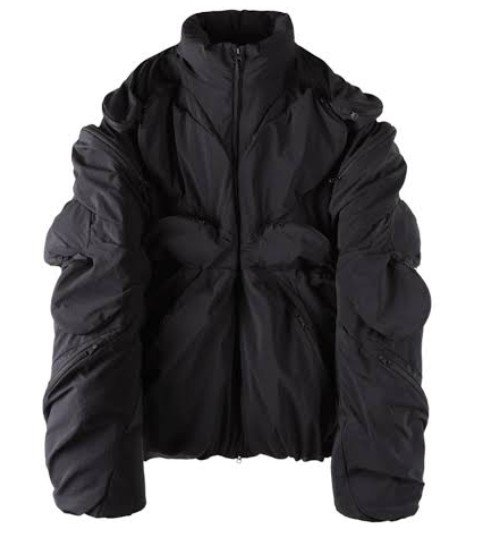

In [23]:
import os
from PIL import Image, ImageOps
from IPython.display import display

# fashion_source.jpg가 없는 경우 기존 receipt.png를 사용하도록 예외 처리
source_filename = "fashion_source.jpg"
if not os.path.exists(source_filename):
    print(f"ℹ️ {source_filename} 파일이 없어 receipt.png를 대신 사용합니다. (원하는 사진이 있다면 파일 탭에 업로드 후 재실행하세요.)")
    source_filename = "receipt.png"

with Image.open(source_filename) as source:
    image = ImageOps.exif_transpose(source).convert("RGB")
    image.thumbnail((1024, 1024))
    image.save("fashion.jpg", format="JPEG", quality=85)

print("✅ 과제용 사진 준비 완료: fashion.jpg")
display(Image.open("fashion.jpg"))

In [24]:
from getpass import getpass

ACCESS_CODE = getpass(
    "Vercel의 APP_ACCESS_CODE와 같은 값을 입력하세요: "
).strip()

if not ACCESS_CODE:
    raise ValueError("접근 코드를 입력해야 합니다.")

print("✅ 접근 코드 설정 완료 — 값은 출력하지 않습니다.")

Vercel의 APP_ACCESS_CODE와 같은 값을 입력하세요: ··········
✅ 접근 코드 설정 완료 — 값은 출력하지 않습니다.


In [13]:
# ============================================================
# [실습 6-0] 접근 코드 정하기 (요청 없음)
# ------------------------------------------------------------
# 13주차 Vercel 에 넣은 APP_ACCESS_CODE 와 같은 값을 적으면 배포 뒤에도 그대로 씁니다
# ============================================================
ACCESS_CODE = "class14-1234"        # ★ (직접 작성) 영어 · 숫자 · 하이픈만 · 남에게 알려 주지 않음
print("✅ 접근 코드를 정했습니다 — 바로 아래 📋 main.py 셀을 실행하면 이 값으로 서버가 켜집니다")

✅ 접근 코드를 정했습니다 — 바로 아래 📋 main.py 셀을 실행하면 이 값으로 서버가 켜집니다


In [14]:
# 📋 main.py · [실습 6-1] 백엔드 — 사진 · 음성 도우미 API (Vercel 에 올릴 main.py · POST 한 번에 요청 1번)
# · 키는 서버 환경 변수 GEMINI_API_KEY · 접근 코드는 APP_ACCESS_CODE (13주차와 같음)
# · 사진 · 음성은 화면(Streamlit)이 base64 글자로 바꿔 JSON 으로 보냄 — Vercel 요청 본문 4.5MB 이하
import base64
import binascii
import os
from typing import Literal

from fastapi import FastAPI, Header, HTTPException
from pydantic import BaseModel, Field
from google import genai
from google.genai import types

MODEL_NAME = "gemini-3.5-flash-lite"
MAX_B64 = 4_000_000                 # base64 글자 수 상한 — Vercel 요청 본문 4.5MB 보다 조금 작게
VOICE_PROMPTS = {
    "받아쓰기": "이 음성을 한국어로 그대로 받아써 줘. 잘 안 들리는 부분은 (?) 로 표시해 줘.",
    "한 줄 요약": "이 음성의 내용을 한 문장으로 요약해 줘.",
    "영어로 번역": "이 음성의 내용을 자연스러운 영어로 번역해 줘.",
}
app = FastAPI(title="사진 · 음성 도우미 API", description="사진이나 음성을 base64 로 보내면 Gemini 가 읽고 답합니다.")


class PhotoRequest(BaseModel):
    image_b64: str = Field(min_length=1, description="사진(JPEG · PNG)을 base64 로 바꾼 글자")
    mime_type: Literal["image/jpeg", "image/png"] = "image/jpeg"
    question: str = Field(default="이 사진에 무엇이 있는지 3문장 이내로 설명해 줘.", max_length=300)


class VoiceRequest(BaseModel):
    audio_b64: str = Field(min_length=1, description="녹음(WAV)을 base64 로 바꾼 글자")
    task: Literal["받아쓰기", "한 줄 요약", "영어로 번역"] = "받아쓰기"


class Answer(BaseModel):
    answer: str
    tokens: int | None = None


def check_access(access_code):
    """APP_ACCESS_CODE 가 정해져 있으면, 요청 헤더 X-Access-Code 가 같아야만 통과"""
    expected = os.environ.get("APP_ACCESS_CODE")
    if expected and access_code != expected:
        raise HTTPException(status_code=401, detail="접근 코드가 틀렸습니다 — 헤더 X-Access-Code 를 확인하세요")


def check_b64(text):
    """base64 글자가 맞는지 · 너무 크지 않은지 먼저 검사 — 틀리면 Gemini 까지 가지 않음"""
    if len(text) > MAX_B64:
        raise HTTPException(status_code=413, detail="파일이 너무 큽니다 — 사진은 줄이고, 녹음은 짧게 보내세요")
    try:
        base64.b64decode(text, validate=True)
    except (binascii.Error, ValueError):
        raise HTTPException(status_code=422, detail="base64 글자가 아닙니다 — 화면에서 b64encode 했는지 확인하세요")


def get_client():
    api_key = os.environ.get("GEMINI_API_KEY")
    if not api_key:
        raise HTTPException(status_code=503, detail="서버에 GEMINI_API_KEY 가 없습니다 — 환경 변수를 확인하세요")
    return genai.Client(
        api_key=api_key,
        http_options=types.HttpOptions(timeout=120_000, retry_options=types.HttpRetryOptions(http_status_codes=[500, 503])),
    )


def ask(text, part):
    """글 부분 + 사진(음성) 부분을 Gemini 에 보내고 Answer 로 돌려줌"""
    client = get_client()                           # 변수에 담아 둠 (9주차 — 담지 않으면 요청 전에 닫힘)
    try:
        reply = client.interactions.create(model=MODEL_NAME, store=False, input=[{"type": "text", "text": text}, part])
    except Exception as error:
        code = getattr(error, "status_code", None)
        if code == 429:
            raise HTTPException(status_code=429, detail="Gemini 무료 한도를 넘었습니다 — 1분 뒤 다시 요청하세요")
        raise HTTPException(status_code=502, detail=f"Gemini 요청 실패 (상태 번호 {code})")
    return Answer(answer=reply.output_text, tokens=reply.usage.total_tokens)


@app.get("/")
def home():
    return {"message": "사진 · 음성 도우미 API 입니다. /docs 에서 사용법을 보세요.", "tasks": list(VOICE_PROMPTS)}


@app.post("/describe", response_model=Answer)
def describe(request: PhotoRequest, x_access_code: str | None = Header(default=None)):
    check_access(x_access_code)                     # ① 접근 코드
    check_b64(request.image_b64)                    # ② 크기 · base64 검사
    return ask(request.question, {"type": "image", "data": request.image_b64, "mime_type": request.mime_type})


@app.post("/listen", response_model=Answer)
def listen(request: VoiceRequest, x_access_code: str | None = Header(default=None)):
    check_access(x_access_code)
    check_b64(request.audio_b64)
    return ask(VOICE_PROMPTS[request.task], {"type": "audio", "data": request.audio_b64, "mime_type": "audio/wav"})

✅ main.py 저장 · API 서버 켜짐 — 만든 주소 :
   · GET   /
   · POST  /describe
   · POST  /listen
ℹ️ 서버는 Colab 컴퓨터 안(localhost:8000)에 있음 — 내 PC 브라우저 주소창으로는 열리지 않음 → 아래 🧪 셀의 call() 로 부르기
👉 배포할 때는 이 셀 전체를 복사(Ctrl+A → Ctrl+C) → GitHub 의 main.py 에 붙여 넣기 → Commit


In [ ]:
# ============================================================
# 🧪 [실습 6-2] 백엔드 시험 — 사진 · 음성 · 접근 코드 · 잘못된 base64 (요청 2번)
# ============================================================
image_text = base64.b64encode(open("receipt.png", "rb").read()).decode("utf-8")
voice_text = base64.b64encode(open("voice.wav", "rb").read()).decode("utf-8")
key_header = {"X-Access-Code": ACCESS_CODE}

call("GET", "/")
call("POST", "/describe", {"image_b64": image_text, "mime_type": "image/png", "question": "가게 이름과 합계만 알려 줘."}, headers=key_header)
call("POST", "/listen", {"audio_b64": voice_text, "task": "한 줄 요약"}, headers=key_header)
call("POST", "/describe", {"image_b64": image_text}, headers={"X-Access-Code": "wrong-code"})        # → 401 (요청 없음)
call("POST", "/describe", {"image_b64": "이건 base64 가 아님"}, headers=key_header)                 # → 422 (요청 없음)

GET / → 상태 번호 200
{
  "message": "사진 · 음성 도우미 API 입니다. /docs 에서 사용법을 보세요.",
  "tasks": [
    "받아쓰기",
    "한 줄 요약",
    "영어로 번역"
  ]
}
POST /describe → 상태 번호 200
{
  "answer": "폴리 카페, 15,300원",
  "tokens": 1104
}
POST /listen → 상태 번호 200
{
  "answer": "오늘 점심은 학생 식당에서 깁밥을 먹었습니다.",
  "tokens": 274
}
POST /describe → 상태 번호 200
{
  "answer": "이 이미지는 '폴리 카페'의 영수증을 보여줍니다. 주문 내역은 아메리카노 2잔, 크루아상 1개, 치즈케이크 1개이며, 총합은 15,300원입니다. 결제 방식은 카드 결제임을 알 수 있습니다.",
  "tokens": 1169
}
POST /describe → 상태 번호 422
{
  "detail": "base64 글자가 아닙니다 — 화면에서 b64encode 했는지 확인하세요"
}


<Response [422]>

> 👀 **직접 확인** — 401 · 422 는 Gemini 까지 가지 않았습니다. 왜 그런지 main.py 의 `describe` 함수에서 ① ② 순서를 찾아보세요.

---
# STEP 7. 화면 — Streamlit 이 내 API 를 부름 (실습 G · 2단계)

화면 `app.py` 에는 **Gemini 도 키도 없습니다.** 사진을 줄여 base64 로 바꾸고, `requests.post` 로 내 API 에 보낸 뒤 답을 보여 줍니다.

https://share.streamlit.io/

In [25]:
# 📋 app.py · [실습 7-1] 화면 — 사진 · 음성 도우미 (Community Cloud 에 올릴 app.py · 분석 한 번에 요청 1번)
# · 이 화면에는 Gemini 키가 없음 — 사진 · 음성을 내 API(Vercel)로 보내고 답만 받아 보여 줌
# · Secrets 두 줄 : API_URL (내 vercel.app 주소) · APP_ACCESS_CODE (Vercel 과 같은 값)
import base64
import io
import os

import requests
import streamlit as st
from PIL import Image

MAX_SIDE = 1024                     # 사진의 긴 쪽을 1024px 이하로 줄여 보냄 — Vercel 요청 본문 4.5MB 안에 들도록

try:
    API_URL = st.secrets["API_URL"]                  # Secrets 의 이름으로 꺼냄 (대괄호 안에 주소를 쓰지 않음)
except Exception:
    API_URL = "http://localhost:8000"                # Secrets 가 없으면(Colab 점검) 같은 런타임의 API 서버
try:
    ACCESS_CODE = st.secrets["APP_ACCESS_CODE"]
except Exception:
    ACCESS_CODE = ""

st.set_page_config(page_title="사진 · 음성 도우미", page_icon="📷")
st.title("📷 사진 · 음성 도우미")
st.caption(f"화면은 Streamlit · 일은 내 API 가 합니다 · API 주소 : {API_URL} · 얼굴 · 신분증 · 남의 목소리는 올리지 마세요")


def photo_b64(raw):
    """사진을 긴 쪽 1024px 이하 JPEG 로 줄이고 base64 글자로 바꾼다"""
    image = Image.open(io.BytesIO(raw)).convert("RGB")
    image.thumbnail((MAX_SIDE, MAX_SIDE))
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=85)
    return base64.b64encode(buffer.getvalue()).decode("utf-8")


def call_api(path, body):
    """내 API 에 JSON 을 보내고 답 또는 오류를 화면에 보여 준다"""
    try:
        response = requests.post(f"{API_URL}{path}", json=body, headers={"X-Access-Code": ACCESS_CODE}, timeout=120)
    except requests.RequestException:
        st.error("❌ API 서버에 닿지 못함 — 화면 위 'API 주소' 가 내 vercel.app 주소인지 확인하세요.")
        return
    if response.status_code == 200:
        data = response.json()
        st.markdown(data["answer"])
        st.caption(f"상태 번호 200 · 토큰 {data['tokens']}")
    else:
        try:
            detail = response.json().get("detail")
        except ValueError:
            detail = response.text[:100]
        st.error(f"❌ 상태 번호 {response.status_code} : {detail}")


photo_tab, voice_tab = st.tabs(["📷 사진", "🎙️ 음성"])

with photo_tab:
    question = st.text_input("사진에 대한 질문", value="이 사진에 무엇이 있는지 3문장 이내로 설명해 줘.")
    camera = st.camera_input("카메라로 찍기") if st.toggle("카메라 켜기") else None
    upload = st.file_uploader("또는 사진 파일 올리기", type=["png", "jpg", "jpeg", "webp"])
    photo = camera or upload
    if photo is not None:
        st.image(photo, width=240)
    if st.button("사진 분석하기", key="photo_go", disabled=photo is None):
        with st.spinner("내 API 에 묻는 중..."):
            call_api("/describe", {"image_b64": photo_b64(photo.getvalue()), "question": question})
    if os.path.exists("receipt.png") and st.button("예시 사진(영수증)으로 해 보기", key="photo_sample"):
        st.image("receipt.png", width=240)
        with st.spinner("내 API 에 묻는 중..."):
            call_api("/describe", {"image_b64": photo_b64(open("receipt.png", "rb").read()), "question": question})

with voice_tab:
    task = st.selectbox("할 일", ["받아쓰기", "한 줄 요약", "영어로 번역"])
    voice = st.audio_input("녹음하기 (마이크 버튼 → 말하기 → 정지 · 1분 이내)")
    if st.button("음성 분석하기", key="voice_go", disabled=voice is None):
        with st.spinner("내 API 에 묻는 중..."):
            call_api("/listen", {"audio_b64": base64.b64encode(voice.getvalue()).decode("utf-8"), "task": task})
    if os.path.exists("voice.wav") and st.button("예시 음성으로 해 보기", key="voice_sample"):
        st.audio("voice.wav")
        with st.spinner("내 API 에 묻는 중..."):
            call_api("/listen", {"audio_b64": base64.b64encode(open("voice.wav", "rb").read()).decode("utf-8"), "task": task})

✅ 오류 없음 — app.py 로 저장했습니다. 처음 화면 : ['📷 사진 · 음성 도우미'] / 입력칸 : ['사진에 대한 질문'] / 버튼 : ['사진 분석하기', '예시 사진(영수증)으로 해 보기', '음성 분석하기', '예시 음성으로 해 보기']


In [ ]:
# ============================================================
# 🧪 [실습 7-2] Community Cloud 의 Secrets 를 흉내 내어 화면 시험 (요청 1번)
# ============================================================
for code_value in [ACCESS_CODE, ""]:                       # 맞는 코드 → 200 · 코드 없음 → 401 (요청 없음)
    app_test = AppTest.from_file(os.path.abspath("app.py"), default_timeout=120)
    app_test.secrets["API_URL"] = "http://localhost:8000"   # 배포 뒤에는 Secrets 의 API_URL 이 내 vercel.app 주소
    app_test.secrets["APP_ACCESS_CODE"] = code_value
    app_test.run()
    app_test.button(key="photo_sample").click().run()
    shown = app_test.error[0].value if app_test.error else app_test.markdown[-1].value[:80]
    print("접근 코드", "있음" if code_value else "없음", "→", shown)

### 실습 7-3 — 배포 : 백엔드 먼저, 화면은 그다음
**① 백엔드 (my-ai-api → Vercel)**
1. GitHub `my-ai-api` → `main.py` → ✏️ → 위 📋 main.py 셀 **코드 안을 클릭** → Ctrl+A · Ctrl+C → 붙여 넣기 → **Commit**
2. Vercel 이 자동으로 다시 배포 → Deployments 맨 위가 **Ready** 인지 확인 (`requirements.txt` 는 13주차 그대로)
3. 환경 변수 `GEMINI_API_KEY` · `APP_ACCESS_CODE` 는 13주차 것 그대로 (없으면 **Add Environment Variable** → Save → **Redeploy**)
4. `https://내프로젝트.vercel.app/docs` 에 `POST /describe` · `POST /listen` 이 보이면 성공

**② 화면 (streamlit-lab → Community Cloud)**
1. GitHub `streamlit-lab` → `app.py` → ✏️ → 위 📋 app.py 셀 전체 붙여 넣기 → **Commit**
2. 예시 파일 올리기(선택) — 📁 `receipt.png` · `voice.wav` ⋮ → 다운로드 → **Add file → Upload files** → Commit
3. <https://share.streamlit.io> → 앱 ⋮ → **Settings → Secrets** 에 두 줄 (13주차 실습 H 와 같음 · `GEMINI_API_KEY` 줄은 지워도 됨)
   ```toml
   API_URL = "https://내프로젝트.vercel.app"
   APP_ACCESS_CODE = "Vercel 과 같은 코드"
   ```
4. **휴대폰**으로 앱 열기 → 화면 위 'API 주소' 가 vercel.app 인지 → 카메라 켜기 → 찍기 → 사진 분석하기 · 🎙️ 녹음 → 음성 분석하기

| 화면에 보이는 것 | 원인 · 고치는 법 |
|---|---|
| API 주소가 `http://localhost:8000` · ❌ 닿지 못함 | Secrets 에 `API_URL` 없음 · 이름 오타 (`st.secrets["API_URL"]`) |
| ❌ 상태 번호 401 | Secrets 의 `APP_ACCESS_CODE` 가 Vercel 값과 다름 |
| ❌ 상태 번호 413 | 파일이 너무 큼 — 녹음을 1분 이내로 (Vercel 은 4.5MB 넘으면 `FUNCTION_PAYLOAD_TOO_LARGE`) |
| ❌ 상태 번호 503 | Vercel 환경 변수 `GEMINI_API_KEY` 없음 · Redeploy 안 함 |
| ❌ 상태 번호 404 | 백엔드를 아직 이번 main.py 로 바꾸지 않음 (`/describe` 가 없음) |
| 카메라 · 마이크가 켜지지 않음 | 주소창 🔒 → 카메라 · 마이크 허용 |

---
# STEP 8. 심화 ① 물체 위치 찾기 — 상자 그리기 (실습 H · 약 20분)

Gemini 는 사진 속 물체의 위치를 **[ymin, xmin, ymax, xmax]** 상자로 돌려줄 수 있습니다. 값은 사진 크기와 상관없이 **0~1000** 으로 맞춘 숫자라서, 실제 픽셀로 바꿔 그립니다.

빨간색 동그라미     [197, 99, 574, 336]
파란색 네모       [369, 429, 843, 670]
초록색 세모       [146, 666, 572, 936]


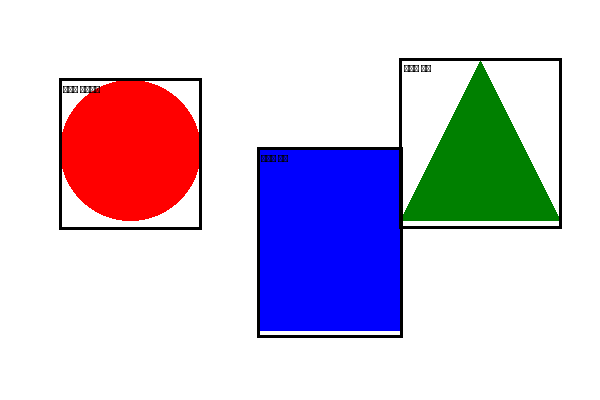

In [15]:
# ============================================================
# [실습 8-1] 도형 사진 → 위치 JSON → 상자 그리기 (요청 1번)
# ============================================================
from PIL import ImageDraw

shapes = Image.new("RGB", (600, 400), "white")                 # 정답을 아는 사진 : 빨간 원 · 파란 네모 · 초록 세모
pen = ImageDraw.Draw(shapes)
pen.ellipse((60, 80, 200, 220), fill="red")
pen.rectangle((260, 150, 400, 330), fill="blue")
pen.polygon([(480, 60), (560, 220), (400, 220)], fill="green")
shapes.save("shapes.png")

BOX_SCHEMA = {"type": "object", "properties": {"objects": {"type": "array", "items": {"type": "object", "properties": {
    "label": {"type": "string"}, "box_2d": {"type": "array", "items": {"type": "integer"}}}, "required": ["label", "box_2d"]}}},
    "required": ["objects"]}
reply = client.interactions.create(
    model=MODEL_NAME, store=False,
    input=[{"type": "text", "text": "사진 속 도형마다 이름(색 + 모양)과 위치 box_2d [ymin, xmin, ymax, xmax] (0~1000) 를 알려 줘."},
           image_part("shapes.png")],
    response_format={"type": "text", "mime_type": "application/json", "schema": BOX_SCHEMA},
)
found = json.loads(reply.output_text)["objects"]

boxed = shapes.copy()
pen = ImageDraw.Draw(boxed)
width, height = boxed.size
for item in found:
    if len(item["box_2d"]) != 4:
        continue
    ymin, xmin, ymax, xmax = item["box_2d"]
    box = (xmin * width / 1000, ymin * height / 1000, xmax * width / 1000, ymax * height / 1000)   # 0~1000 → 픽셀
    pen.rectangle(box, outline="black", width=3)
    pen.text((box[0] + 4, box[1] + 4), item["label"], fill="black")
    print(f"{item['label']:12} {item['box_2d']}")
boxed.save("boxed.png")
display(boxed)

> 👀 **직접 확인** — 상자가 도형을 잘 감싸나요? 정답 위치(픽셀) : 빨간 원 (60,80)~(200,220) · 파란 네모 (260,150)~(400,330) · 초록 세모 (400,60)~(560,220)

### 🔥 도전
| 바꿔 볼 것 | 예 | 볼 것 |
|---|---|---|
| 내 사진으로 | 책상 위 물건 사진을 올려 `image_part("내사진.jpg")` | 작은 물건 · 겹친 물건도 찾나 |
| 찾을 것만 지정 | "초록색인 것만 찾아 줘" | 조건에 맞는 것만 상자가 생기나 |
| 개수 세기 | box 개수로 "물건 몇 개" 출력 | AI 의 답 대신 코드로 셈 |

---
# STEP 9. 심화 ② 사진 여러 장 비교 · 이어 묻기 (실습 I · 약 20분)

요청 하나에 사진을 여러 장 넣을 수 있습니다. 대화를 이어 갈 때는 11주차처럼 **기록(history)** 을 함께 보내는데, 기록 안의 사진도 **매번 다시 토큰으로 셉니다.**

In [ ]:
# ============================================================
# [실습 9-1] 영수증 두 장 비교 → 이어서 묻기 (요청 2번)
# ============================================================
second = Image.open("receipt.png").copy()                      # 두 번째 영수증 : 크루아상 줄을 지우고 다시 씀
pen = ImageDraw.Draw(second)
pen.rectangle((40, 185, 440, 225), fill="white")
pen.text((40, 190), "베이글", font=ImageFont.truetype(FONT, 22), fill="black")
pen.text((250, 190), "x1", font=ImageFont.truetype(FONT, 22), fill="black")
pen.text((330, 190), "3,300원", font=ImageFont.truetype(FONT, 22), fill="black")
second.save("receipt2.png")

first_turn = {"type": "user_input", "content": [
    {"type": "text", "text": "두 영수증에서 달라진 메뉴와 금액만 알려 줘."},
    image_part("receipt.png"), image_part("receipt2.png")]}
reply = client.interactions.create(model=MODEL_NAME, store=False, input=[first_turn])
print("1번째 답 :", reply.output_text)
print("   입력 토큰 :", reply.usage.total_input_tokens)

history = [first_turn] + [step.model_dump(mode="json") for step in reply.steps]    # 사진이 든 첫 질문도 기록에 남음
history.append({"type": "user_input", "content": [{"type": "text", "text": "그럼 두 번째 영수증의 합계는 얼마가 맞아?"}]})
reply = client.interactions.create(model=MODEL_NAME, store=False, input=history)
print("2번째 답 :", reply.output_text)
print("   입력 토큰 :", reply.usage.total_input_tokens, "← 사진 두 장이 기록에 있어 또 셈")

1번째 답 : 첫 번째 영수증에는 **크루아상 (3,800원)**이 있고, 두 번째 영수증에는 **베이글 (3,300원)**로 변경되어 있습니다.
   입력 토큰 : 2176
2번째 답 : 두 번째 영수증의 올바른 합계는 **14,800원**입니다. 

* 아메리카노: 9,000원
* 베이글: 3,300원
* 치즈케이크: 2,500원
*(총합: 14,800원)*

현재 영수증에 적힌 15,300원은 잘못 계산된 금액입니다.
   입력 토큰 : 2238 ← 사진 두 장이 기록에 있어 또 셈


> 👀 **직접 확인** — 두 번째 영수증의 합계 칸은 고치지 않았습니다(15,300원 그대로). 메뉴를 더하면 14,800원인데, AI 는 어느 쪽을 맞다고 하나요? 2번째 요청의 입력 토큰이 왜 줄지 않았을까요?

### 🔥 도전
| 바꿔 볼 것 | 예 | 볼 것 |
|---|---|---|
| 기록에서 사진 빼기 | 2번째 요청 전에 `history[0]["content"]` 를 글만 남김 | 토큰이 줄고 답은 그대로인가 |
| 전후 비교 | 정리 전 · 정리 후 책상 사진 두 장 | "무엇이 달라졌나" 를 잘 찾나 |
| 사진 + 음성 함께 | `[글, image_part(...), audio_part(...)]` | 한 요청에 종류가 다른 부분 셋 |

---
# 📝 오늘의 과제 — 나만의 멀티모달 서비스 (백엔드 + 화면)

사진을 보내면 내가 정한 칸(JSON)으로 정리해 주는 서비스를 **백엔드(Vercel) + 화면(Streamlit)** 으로 나눠 배포합니다.
★ 고칠 곳은 **백엔드 main.py 에만** 있습니다. 화면 app.py 는 이름 · 칸을 내 API 의 `GET /` 에서 가져오므로 고칠 곳이 없습니다.

### 조건
1. 📋 main.py 의 ★ 세 곳(이름 · 사진을 보고 할 일 · 결과 칸 3~5개)을 **내 주제**로 바꿈
2. 백엔드 = 13주차 과제 저장소(`my-api-주제`)의 `main.py` 교체 → Vercel 배포 · 환경 변수 `GEMINI_API_KEY` · `APP_ACCESS_CODE`
3. 화면 = 13주차 과제 3단계 저장소(`my-app-주제`)의 `app.py` 교체 + 예시 사진 → Secrets `API_URL` · `APP_ACCESS_CODE`
4. Colab 🧪 두 셀(백엔드 · 화면)에서 결과가 나옴
5. **휴대폰 카메라로 찍어** 결과 표가 나오는지 확인
6. 예시 사진은 내가 찍은 사진(얼굴 · 개인정보 없음) 또는 코드로 만든 그림 · 팀 주제로 해도 됨

| 주제 예 | 결과 칸 예 |
|---|---|
| 냉장고 사진 → 요리 추천 | 재료 · 추천 요리 · 걸리는 시간 · 조리 순서 |
| 분리수거 도우미 | 물건 · 재질 · 버리는 방법 · 주의할 점 |
| 강의 판서 정리 | 주제 · 핵심 3줄 · 모르는 용어 · 복습 질문 |

### 과제 1단계 — 백엔드

In [ ]:
# 📋 main.py · [과제 백엔드] 나만의 멀티모달 API — 사진을 받아 정해 둔 칸(JSON)으로 정리 (Vercel 에 올릴 main.py · POST 한 번에 요청 1번)
# · ★ (직접 작성) 표시가 붙은 곳만 내 주제로 바꾸면 됨 — 화면(app.py)은 고칠 곳 없음
# · 키는 환경 변수 GEMINI_API_KEY · 접근 코드는 APP_ACCESS_CODE (코드 · 저장소에 적지 않음)
import base64
import binascii
import json
import os

from fastapi import FastAPI, Header, HTTPException
from pydantic import BaseModel, Field
from google import genai
from google.genai import types

MODEL_NAME = "gemini-3.5-flash-lite"

# ★ (직접 작성) ① 서비스 이름 · 아이콘 · 한 줄 소개 — 화면이 GET / 로 받아 제목으로 씀
APP_TITLE = "영수증 가계부 도우미"
APP_ICON = "🧾"
APP_DESCRIPTION = "영수증 사진을 찍으면 가게 · 날짜 · 합계를 정리하고 한마디 조언을 해 줍니다"

# ★ (직접 작성) ② 사진을 보고 할 일 — 역할 · 할 일 · 모를 때
PROMPT = """너는 대학생의 가계부를 도와주는 도우미야.
사진이 영수증이면 아래 칸을 채워. 사진에서 읽을 수 없는 칸은 '확인 불가' 라고 적어.
영수증이 아니면 모든 칸에 '영수증이 아님' 이라고 적어."""

# ★ (직접 작성) ③ 결과로 받을 칸 이름 : 설명 (3~5개)
FIELDS = {
    "가게": "가게 이름",
    "날짜": "결제 날짜 (YYYY-MM-DD)",
    "합계": "합계 금액 (예: 15,300원)",
    "조언": "이 지출에 대한 한 문장 조언",
}

SCHEMA = {"type": "object", "properties": {name: {"type": "string", "description": text} for name, text in FIELDS.items()},
          "required": list(FIELDS)}
app = FastAPI(title=APP_TITLE, description=APP_DESCRIPTION)


class PhotoRequest(BaseModel):
    image_b64: str = Field(min_length=1, max_length=4_000_000, description="사진(JPEG)을 base64 로 바꾼 글자")


class Result(BaseModel):
    result: dict[str, str]
    tokens: int | None = None


def check_access(access_code):
    expected = os.environ.get("APP_ACCESS_CODE")
    if expected and access_code != expected:
        raise HTTPException(status_code=401, detail="접근 코드가 틀렸습니다 — 헤더 X-Access-Code 를 확인하세요")


def get_client():
    api_key = os.environ.get("GEMINI_API_KEY")
    if not api_key:
        raise HTTPException(status_code=503, detail="서버에 GEMINI_API_KEY 가 없습니다 — 환경 변수를 확인하세요")
    return genai.Client(
        api_key=api_key,
        http_options=types.HttpOptions(timeout=120_000, retry_options=types.HttpRetryOptions(http_status_codes=[500, 503])),
    )


@app.get("/")
def home():
    """화면이 제목 · 아이콘 · 소개 · 칸 이름을 가져가는 주소 (요청 없음)"""
    return {"name": APP_TITLE, "icon": APP_ICON, "description": APP_DESCRIPTION, "fields": list(FIELDS)}


@app.post("/analyze", response_model=Result)
def analyze(request: PhotoRequest, x_access_code: str | None = Header(default=None)):
    check_access(x_access_code)
    try:
        base64.b64decode(request.image_b64, validate=True)
    except (binascii.Error, ValueError):
        raise HTTPException(status_code=422, detail="base64 글자가 아닙니다")
    client = get_client()
    try:
        reply = client.interactions.create(
            model=MODEL_NAME, store=False,
            input=[{"type": "text", "text": PROMPT}, {"type": "image", "data": request.image_b64, "mime_type": "image/jpeg"}],
            response_format={"type": "text", "mime_type": "application/json", "schema": SCHEMA},
        )
    except Exception as error:
        code = getattr(error, "status_code", None)
        raise HTTPException(status_code=429 if code == 429 else 502, detail=f"Gemini 요청 실패 (상태 번호 {code})")
    try:
        result = json.loads(reply.output_text)
    except json.JSONDecodeError:
        raise HTTPException(status_code=502, detail="답이 JSON 모양이 아닙니다 — 다시 보내 보세요")
    return Result(result={name: str(result.get(name, "")) for name in FIELDS}, tokens=reply.usage.total_tokens)

In [ ]:
# ============================================================
# 🧪 [과제 1단계] 백엔드 시험 — GET / 와 POST /analyze (요청 1번)
# ============================================================
call("GET", "/")
call("POST", "/analyze", {"image_b64": base64.b64encode(open("receipt.png", "rb").read()).decode("utf-8")},
     headers={"X-Access-Code": ACCESS_CODE})

### 과제 2단계 — 화면 (고칠 곳 없음)

In [ ]:
# 📋 app.py · [과제 화면] 나만의 멀티모달 앱 — 고칠 곳 없음 · 제목 · 칸은 내 API 의 GET / 에서 가져옴 (분석 한 번에 요청 1번)
# · Secrets 두 줄 : API_URL (내 과제 API 의 vercel.app 주소) · APP_ACCESS_CODE (Vercel 과 같은 값)
# · 예시 사진(receipt.png 또는 내 사진)을 저장소에 같이 올리면 '예시 사진으로 해 보기' 버튼이 생김
import base64
import io
import os

import requests
import streamlit as st
from PIL import Image

EXAMPLE_IMAGE = "receipt.png"

try:
    API_URL = st.secrets["API_URL"]
except Exception:
    API_URL = "http://localhost:8000"
try:
    ACCESS_CODE = st.secrets["APP_ACCESS_CODE"]
except Exception:
    ACCESS_CODE = ""

try:                                                 # GET / — 이름 · 아이콘 · 소개 · 칸 (Gemini 요청 없음)
    info = requests.get(f"{API_URL}/", timeout=30).json()
    fields = info["fields"]
except (requests.RequestException, ValueError, KeyError):
    st.error("❌ API 서버에 닿지 못함 — Secrets 의 API_URL 이 내 vercel.app 주소인지 확인하세요.")
    st.caption(f"API 주소 : {API_URL}")
    st.stop()

st.set_page_config(page_title=info.get("name", "나만의 AI"), page_icon=info.get("icon", "📷"))
st.title(f"{info.get('icon', '')} {info.get('name', '나만의 AI')}")
st.caption(f"{info.get('description', '')} · 결과 칸 : {' · '.join(fields)} · 얼굴 · 신분증 · 카드 번호가 보이는 사진은 올리지 마세요")


def photo_b64(raw):
    """사진을 긴 쪽 1024px 이하 JPEG 로 줄이고 base64 글자로 바꾼다"""
    image = Image.open(io.BytesIO(raw)).convert("RGB")
    image.thumbnail((1024, 1024))
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=85)
    return base64.b64encode(buffer.getvalue()).decode("utf-8")


def analyze(raw):
    try:
        response = requests.post(f"{API_URL}/analyze", json={"image_b64": photo_b64(raw)},
                                 headers={"X-Access-Code": ACCESS_CODE}, timeout=120)
    except requests.RequestException:
        st.error("❌ API 서버에 닿지 못함 — 잠시 뒤 다시 눌러 보세요.")
        return
    if response.status_code != 200:
        st.error(f"❌ 상태 번호 {response.status_code} : {response.json().get('detail')}")
        return
    data = response.json()
    st.table([{"칸": name, "내용": data["result"].get(name, "")} for name in fields])
    st.caption(f"상태 번호 200 · 토큰 {data['tokens']}")


camera = st.camera_input("카메라로 찍기") if st.toggle("카메라 켜기") else None
upload = st.file_uploader("또는 사진 파일 올리기", type=["png", "jpg", "jpeg", "webp"])
photo = camera or upload
if photo is not None:
    st.image(photo, width=240)
if st.button("정리하기", key="go", disabled=photo is None):
    with st.spinner("내 API 에 묻는 중..."):
        analyze(photo.getvalue())
if os.path.exists(EXAMPLE_IMAGE) and st.button("예시 사진으로 해 보기", key="sample"):
    st.image(EXAMPLE_IMAGE, width=240)
    with st.spinner("내 API 에 묻는 중..."):
        analyze(open(EXAMPLE_IMAGE, "rb").read())

In [ ]:
# ============================================================
# 🧪 [과제 2단계] 화면 시험 — 예시 사진 버튼 (요청 1번)
# ============================================================
app_test = AppTest.from_file(os.path.abspath("app.py"), default_timeout=120)
app_test.secrets["API_URL"] = "http://localhost:8000"       # 배포 뒤에는 내 과제 API 의 vercel.app 주소
app_test.secrets["APP_ACCESS_CODE"] = ACCESS_CODE
app_test.run()
print("화면 제목 :", app_test.title[0].value if app_test.title else app_test.error[0].value)
app_test.button(key="sample").click().run()
print(app_test.error[0].value if app_test.error else app_test.table[0].value)

### 과제 3단계 — 배포 · 휴대폰 시험
1. 백엔드 : `my-api-주제` 의 `main.py` 교체 → Commit → Vercel **Ready** → `…vercel.app/docs` 에 `POST /analyze`
2. 화면 : `my-app-주제` 의 `app.py` 교체 + 예시 사진 올리기 → Secrets 두 줄 (`API_URL` · `APP_ACCESS_CODE`)
3. 휴대폰으로 화면 주소를 열어 찍기 → 정리하기 → 결과 표

### ✏️ 정리 칸 (직접 작성)
- 내 API 주소 (`https://….vercel.app`) :
- 내 화면 주소 (`https://….streamlit.app`) :
- 주제와 결과 칸 :
- 휴대폰으로 찍어 본 결과 (맞은 칸 · 틀린 칸) :
- 실습 5 에서 본 큰 사진 · 줄인 사진의 입력 토큰 :
- 화면(Streamlit)과 백엔드(Vercel)에 각각 무엇을 넣었나 (키 · 주소 · 접근 코드) :

---
## 📚 더 알아보기 (2026-11-09 접속 확인)
| 자료 | 주소 |
|---|---|
| Gemini — 이미지 이해 (Interactions · 한국어) | <https://ai.google.dev/gemini-api/docs/interactions/image-understanding?hl=ko> |
| Gemini — 오디오 이해 | <https://ai.google.dev/gemini-api/docs/interactions/audio> |
| Gemini — 문서(PDF) 처리 | <https://ai.google.dev/gemini-api/docs/interactions/document-processing> |
| Streamlit — st.camera_input | <https://docs.streamlit.io/develop/api-reference/widgets/st.camera_input> |
| Streamlit — st.audio_input | <https://docs.streamlit.io/develop/api-reference/widgets/st.audio_input> |